<a href="https://colab.research.google.com/github/Vishesh-Goyal7/NARAD-QC/blob/main/NARAD_QC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NARAD-QC
### Network Architecture for Routing, Authentication and Delivery in Quantum Communications

## Phase 0 : 06072026-16:15:32 - 06072026-16:48:53

Goal : Rebuild point to point CrypTon key generation and AES baseline.

Objective : Prove the original point-to-point system is working as the baseline.

In [ ]:
# @title Dependency Installation for Phase 0

!pip install qiskit qiskit-aer pycryptodome pandas matplotlib --quiet

In [ ]:
# @title Imports and Global Config

import time
import secrets
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

from Crypto.Cipher import AES
from Crypto.Random import get_random_bytes

RNG = np.random.default_rng()
BACKEND = AerSimulator()

QBER_CUTOFF = 0.11
NONCE_LEN = 12

In [ ]:
# @title AES-GCM Engine

def aes_gcm_encrypt(data: bytes, key: bytes) -> bytes:
    nonce = get_random_bytes(NONCE_LEN)
    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    ciphertext, tag = cipher.encrypt_and_digest(data)
    return nonce + ciphertext + tag


def aes_gcm_decrypt(blob: bytes, key: bytes) -> bytes:
    nonce = blob[:NONCE_LEN]
    rest = blob[NONCE_LEN:]
    ciphertext = rest[:-16]
    tag = rest[-16:]

    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    return cipher.decrypt_and_verify(ciphertext, tag)

In [ ]:
# @title BB84 Step 1 : QRNG

def random_bitstring(n: int) -> list[int]:
    return RNG.integers(0, 2, size=n).tolist()


def random_bases(n: int) -> list[int]:
    return RNG.integers(0, 2, size=n).tolist()

In [ ]:
# @title BB84 Step 2 : Qubit Encoding

def encode_qubits(bits: list[int], bases: list[int]) -> list[QuantumCircuit]:
    circuits = []

    for bit, basis in zip(bits, bases):
        qc = QuantumCircuit(1, 1)

        if bit == 1:
            qc.x(0)

        if basis == 1:
            qc.h(0)

        circuits.append(qc)

    return circuits

In [ ]:
# @title BB84 Step 3 : Measure Qubits With Photon Loss Support

def measure_qubits(
    qubits: list,
    bob_bases: list[int],
    eve_present: bool = False
) -> list:

    measured_bits = []

    for i, prepared_qubit in enumerate(qubits):

        # Photon lost in QuantumLink
        if prepared_qubit is None:
            measured_bits.append(None)
            continue

        circuit = prepared_qubit.copy()

        if eve_present:
            eve_basis = int(RNG.integers(0, 2))

            eve_circuit = circuit.copy()

            if eve_basis == 1:
                eve_circuit.h(0)

            eve_circuit.measure(0, 0)

            transpiled_eve = transpile(eve_circuit, BACKEND)
            eve_result = BACKEND.run(
                transpiled_eve,
                shots=1,
                memory=True
            ).result()

            eve_bit = int(eve_result.get_memory()[0])

            circuit = QuantumCircuit(1, 1)

            if eve_bit == 1:
                circuit.x(0)

            if eve_basis == 1:
                circuit.h(0)

        if bob_bases[i] == 1:
            circuit.h(0)

        circuit.measure(0, 0)

        transpiled_bob = transpile(circuit, BACKEND)
        bob_result = BACKEND.run(
            transpiled_bob,
            shots=1,
            memory=True
        ).result()

        measured_bits.append(int(bob_result.get_memory()[0]))

    return measured_bits

In [ ]:
# @title QBER, Sifting, and Key Reconciliation With Photon Loss

def sift_keys(
    alice_bits: list[int],
    alice_bases: list[int],
    bob_bits: list,
    bob_bases: list[int]
) -> tuple[list[int], list[int]]:

    alice_sifted = []
    bob_sifted = []

    for i in range(len(alice_bits)):
        if bob_bits[i] is None:
            continue

        if alice_bases[i] == bob_bases[i]:
            alice_sifted.append(alice_bits[i])
            bob_sifted.append(bob_bits[i])

    return alice_sifted, bob_sifted

def calculate_qber(alice_key: list[int], bob_key: list[int]) -> float:
    if len(alice_key) == 0:
        return 1.0

    errors = sum(a != b for a, b in zip(alice_key, bob_key))
    return errors / len(alice_key)

In [ ]:
# @title One BB84 Round

def bb84_round(
    n_qubits: int = 256,
    eve_present: bool = False
) -> dict:

    alice_bits = random_bitstring(n_qubits)
    alice_bases = random_bases(n_qubits)
    bob_bases = random_bases(n_qubits)

    qubits = encode_qubits(alice_bits, alice_bases)
    bob_bits = measure_qubits(qubits, bob_bases, eve_present=eve_present)

    alice_sifted, bob_sifted = sift_keys(
        alice_bits,
        alice_bases,
        bob_bits,
        bob_bases
    )

    qber = calculate_qber(alice_sifted, bob_sifted)

    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,
        "eve_present": eve_present
    }

In [ ]:
# @title Accumulate Session Key

def bits_to_bytes(bits: list[int]) -> bytes:
    usable_len = len(bits) - (len(bits) % 8)
    bits = bits[:usable_len]

    return bytes(
        int("".join(map(str, bits[i:i+8])), 2)
        for i in range(0, usable_len, 8)
    )


def generate_bb84_session_key(
    target_bits: int = 128,
    n_qubits_per_round: int = 256,
    max_rounds: int = 30,
    eve_present: bool = False,
    verbose: bool = True
) -> tuple[bytes, dict]:

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):
        result = bb84_round(
            n_qubits=n_qubits_per_round,
            eve_present=eve_present
        )

        round_logs.append({
            "round": round_id,
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"]
        })

        if verbose:
            print(
                f"Round {round_id}: "
                f"sifted={result['sifted_length']}, "
                f"QBER={result['qber']:.2%}, "
                f"accepted={result['accepted']}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough accepted BB84 key bits."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    metadata = {
        "target_bits": target_bits,
        "rounds_used": len(round_logs),
        "accepted_rounds": sum(r["accepted"] for r in round_logs),
        "rejected_rounds": sum(not r["accepted"] for r in round_logs),
        "total_sifted_bits": sum(r["sifted_length"] for r in round_logs),
        "keygen_time_s": elapsed,
        "round_logs": round_logs
    }

    return key, metadata

In [ ]:
# @title Phase 0 End to End System COMMENTED OUT

# message = b"NARAD-QC Phase 0: CrypTon baseline reconstruction."

# session_key, meta = generate_bb84_session_key(
#     target_bits=128,
#     n_qubits_per_round=256,
#     max_rounds=30,
#     eve_present=False,
#     verbose=True
# )

# ciphertext = aes_gcm_encrypt(message, session_key)
# decrypted = aes_gcm_decrypt(ciphertext, session_key)

# print("\nSession Key:", session_key.hex())
# print("Key Metadata:", meta)
# print("Ciphertext:", ciphertext.hex())
# print("Decrypted:", decrypted.decode())
# print("Roundtrip OK:", decrypted == message)

In [ ]:
# @title Eve Presence Validation COMMENTED OUT

# try:
#     eve_key, eve_meta = generate_bb84_session_key(
#         target_bits=128,
#         n_qubits_per_round=256,
#         max_rounds=5,
#         eve_present=True,
#         verbose=True
#     )

#     print("Unexpectedly generated key with Eve present.")
#     print(eve_meta)

# except RuntimeError as e:
#     print("Eve disrupted key generation as expected.")
#     print(str(e))

## Phase 1 : 06072026-17:08:12 -

Goal : Add distance-dependent photon loss, QBER, keygen latency, and accepted/rejected rounds.

Objective : Evaluate how distance affects QKD in terms of photon loss, QBER, Key generation latency.

Question : How does increasing physical separation affect secure key establishment in CrypTon?

### Phase 1.1

QuantumLink and Node classes

In [ ]:
# @title Node Class Definition

ROLE_USER = "USER"
ROLE_REPEATER = "REPEATER"

class Node:
    def __init__(self, name: str, role: str):
        self.name = name
        self.role = role

    def __str__(self):
        return f"{self.name} ({self.role})"

In [ ]:
# @title Create 2 User Nodes

alice = Node(name="Alice", role=ROLE_USER)
bob = Node(name="Bob", role=ROLE_USER)

print(alice)
print(bob)

In [ ]:
# @title Quantum Link Class

import random
import math

STANDARD_FIBER_ATTENUATION = 0.2  # dB/km


class QuantumLink:
    """
    NARAD-QC Phase 1.1 / 1.2

    Models a physical quantum channel with distance-dependent photon loss.
    Lost photons are represented as None.
    """

    def __init__(
        self,
        source: Node,
        destination: Node,
        distance_km: float,
        attenuation_db_per_km: float = STANDARD_FIBER_ATTENUATION
    ):
        self.source = source
        self.destination = destination
        self.distance_km = distance_km
        self.attenuation = attenuation_db_per_km
        self.status = "ACTIVE"

        # η(d) = 10^(-(αd)/10)
        self.survival_probability = 10 ** (
            -(self.attenuation * self.distance_km) / 10
        )

        self.loss_probability = 1 - self.survival_probability

        self.statistics = {
            "lifetime_sent": 0,
            "lifetime_received": 0,
            "lifetime_lost": 0
        }

    def transmit(self, qubit):
        """
        Transmit one qubit through the quantum link.
        Returns the qubit if it survives, otherwise None.
        """

        self.statistics["lifetime_sent"] += 1

        if random.random() < self.survival_probability:
            self.statistics["lifetime_received"] += 1
            return qubit

        self.statistics["lifetime_lost"] += 1
        return None

    def transmit_batch(self, qubits: list):
        """
        Transmit a batch of qubits.

        Returns:
        - transmitted_qubits: list containing QuantumCircuit objects or None
        - session-level transmission statistics
        """

        transmitted_qubits = []
        survived = 0

        for qubit in qubits:
            received = self.transmit(qubit)
            transmitted_qubits.append(received)

            if received is not None:
                survived += 1

        sent = len(qubits)
        lost = sent - survived

        return {
            "transmitted_qubits": transmitted_qubits,
            "sent": sent,
            "survived": survived,
            "lost": lost,
            "expected_survival_probability": self.survival_probability,
            "observed_survival_probability": survived / sent if sent else 0,
            "survival_percentage": (survived / sent) * 100 if sent else 0
        }

    def reset_statistics(self):
        self.statistics = {
            "lifetime_sent": 0,
            "lifetime_received": 0,
            "lifetime_lost": 0
        }

    def __str__(self):
        return (
            f"\n{'='*60}\n"
            f"Quantum Link\n"
            f"{'='*60}\n"
            f"Source                          : {self.source.name}\n"
            f"Destination                     : {self.destination.name}\n"
            f"Distance                        : {self.distance_km} km\n"
            f"Attenuation                     : {self.attenuation} dB/km\n"
            f"Status                          : {self.status}\n"
            f"Photon Survival Probability     : {self.survival_probability*100:.2f}%\n"
            f"Photon Loss Probability         : {self.loss_probability*100:.2f}%\n"
            f"{'='*60}"
        )

In [ ]:
# @title Testing one Quantum Link

link = QuantumLink(
    source=alice,
    destination=bob,
    distance_km=50
)

print(link)

In [ ]:
# @title Testing Batch Transmission

dummy_qubits = [f"Photon_{i}" for i in range(1000)]

result = link.transmit_batch(dummy_qubits)

print("Transmission Statistics\n")

print(f"Sent        : {result['sent']}")
print(f"Survived    : {result['survived']}")
print(f"Lost        : {result['lost']}")
print(f"Survival %  : {result['survival_percentage']:.2f}%")

In [ ]:
# @title Distance Comparison

distances = [10, 20, 50, 80, 100, 150, 200]

print(
    f"{'Distance':<12}"
    f"{'Survival %':<15}"
    f"{'Loss %':<15}"
)

print("-" * 42)

for d in distances:
    test_link = QuantumLink(alice, bob, d)

    print(
        f"{d:<12}"
        f"{test_link.survival_probability*100:<15.2f}"
        f"{test_link.loss_probability*100:<15.2f}"
    )

### Phase 1.2

Distance --> Attenuation Model --> Testing Over Multiple Distances

In [ ]:
# @title BB84 / Biased-Basis Generator

def random_bases(n: int, z_probability: float = 0.5) -> list[int]:
    """
    Generate random bases.

    0 = Z / computational basis
    1 = X / diagonal basis

    z_probability = 0.5      -> Standard BB84
    z_probability = 0.8      -> Biased BB84
    z_probability = 15/16    -> T12-style biased basis
    """

    return [
        0 if random.random() < z_probability else 1
        for _ in range(n)
    ]


def basis_match_probability(z_probability: float) -> float:
    """
    P(match) = P(Z)^2 + P(X)^2
    """

    return z_probability**2 + (1 - z_probability)**2

In [ ]:
# @title One Distance-Aware BB84 Round With Estimated Photon Budget

import math

def bb84_round_over_link(
    link: QuantumLink,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5
) -> dict:

    p_basis = basis_match_probability(z_probability)

    estimated_photons_required = math.ceil(
        (target_bits * transmission_margin) /
        (p_basis * link.survival_probability)
    )

    n_qubits = max(1, estimated_photons_required)

    alice_bits = random_bitstring(n_qubits)
    alice_bases = random_bases(n_qubits, z_probability=z_probability)
    bob_bases = random_bases(n_qubits, z_probability=z_probability)

    encoded_qubits = encode_qubits(alice_bits, alice_bases)

    transmission = link.transmit_batch(encoded_qubits)
    received_qubits = transmission["transmitted_qubits"]

    bob_bits = measure_qubits(received_qubits, bob_bases, eve_present=eve_present)

    alice_sifted, bob_sifted = sift_keys(alice_bits, alice_bases, bob_bits, bob_bases)

    qber = calculate_qber(alice_sifted, bob_sifted)
    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,
        "eve_present": eve_present,
        "z_probability": z_probability,
        "basis_match_probability": p_basis,
        "target_bits_for_round": target_bits,
        "transmission_margin": transmission_margin,
        "estimated_photons_required": estimated_photons_required,
        "photons_sent": transmission["sent"],
        "photons_received": transmission["survived"],
        "photons_lost": transmission["lost"],
        "expected_survival_probability": transmission["expected_survival_probability"],
        "observed_survival_probability": transmission["observed_survival_probability"]
    }

In [ ]:
# @title Generate Session Key Over Quantum Link

def generate_bb84_session_key_over_link(
    link: QuantumLink,
    target_bits: int = 128,
    max_rounds: int = 100,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5,
    verbose: bool = True
) -> tuple[bytes, dict]:

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):

        remaining_bits = target_bits - len(collected_bits)

        result = bb84_round_over_link(
            link=link,
            target_bits=remaining_bits,
            transmission_margin=transmission_margin,
            eve_present=eve_present,
            z_probability=z_probability
        )

        round_log = {
            "round": round_id,
            "distance_km": link.distance_km,
            "photons_sent": result["photons_sent"],
            "photons_received": result["photons_received"],
            "photons_lost": result["photons_lost"],
            "observed_survival_probability": result["observed_survival_probability"],
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"],
            "z_probability": z_probability,
            "basis_match_probability": result["basis_match_probability"],
            "target_bits_for_round": result["target_bits_for_round"],
            "transmission_margin": result["transmission_margin"],
            "estimated_photons_required": result["estimated_photons_required"],
        }

        round_logs.append(round_log)

        if verbose:
            print(
                f"Round {round_id}: "
                f"distance={link.distance_km} km | "
                f"sent={result['photons_sent']} | "
                f"received={result['photons_received']} | "
                f"sifted={result['sifted_length']} | "
                f"QBER={result['qber']:.2%} | "
                f"accepted={result['accepted']}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough accepted BB84 key bits over the quantum link."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    total_sent = sum(r["photons_sent"] for r in round_logs)
    total_received = sum(r["photons_received"] for r in round_logs)
    total_lost = sum(r["photons_lost"] for r in round_logs)
    total_sifted = sum(r["sifted_length"] for r in round_logs)

    metadata = {
        "source": link.source.name,
        "destination": link.destination.name,
        "distance_km": link.distance_km,
        "target_bits": target_bits,
        "z_probability": z_probability,
        "basis_match_probability": basis_match_probability(z_probability),
        "rounds_used": len(round_logs),
        "accepted_rounds": sum(r["accepted"] for r in round_logs),
        "rejected_rounds": sum(not r["accepted"] for r in round_logs),
        "total_photons_sent": total_sent,
        "total_photons_received": total_received,
        "total_photons_lost": total_lost,
        "observed_survival_probability": total_received / total_sent if total_sent else 0,
        "total_sifted_bits": total_sifted,
        "effective_key_yield": target_bits / total_sent if total_sent else 0,
        "keygen_time_s": elapsed,
        "round_logs": round_logs
    }

    return key, metadata

In [ ]:
# @title Phase 1.2 End-to-End Distance-Aware Test

# distance_link = QuantumLink(
#     source=alice,
#     destination=bob,
#     distance_km=50
# )

# session_key, meta = generate_bb84_session_key_over_link(
#     link=distance_link,
#     target_bits=128,
#     max_rounds=100,
#     eve_present=False,
#     z_probability=0.5,   # Standard BB84
#     verbose=True,
#     transmission_margin = 1.3,
# )

# message = b"NARAD-QC Phase 1.2: Distance-aware BB84 session key."

# ciphertext = aes_gcm_encrypt(message, session_key)
# decrypted = aes_gcm_decrypt(ciphertext, session_key)

# print("\n" + "="*60)
# print("NARAD-QC Phase 1.2 Session Report")
# print("="*60)
# print(f"Source                     : {meta['source']}")
# print(f"Destination                : {meta['destination']}")
# print(f"Distance                   : {meta['distance_km']} km")
# print(f"Target Key Bits            : {meta['target_bits']}")
# print(f"Z-Basis Probability        : {meta['z_probability']}")
# print(f"Basis Match Probability    : {meta['basis_match_probability']*100:.2f}%")
# print(f"Rounds Used                : {meta['rounds_used']}")
# print(f"Total Photons Sent         : {meta['total_photons_sent']}")
# print(f"Total Photons Received     : {meta['total_photons_received']}")
# print(f"Total Photons Lost         : {meta['total_photons_lost']}")
# print(f"Observed Survival          : {meta['observed_survival_probability']*100:.2f}%")
# print(f"Total Sifted Bits          : {meta['total_sifted_bits']}")
# print(f"Effective Key Yield        : {meta['effective_key_yield']*100:.4f}%")
# print(f"Keygen Time                : {meta['keygen_time_s']:.4f} s")
# print(f"AES Roundtrip OK           : {decrypted == message}")
# print("="*60)

In [ ]:
# @title Standard BB84 vs T12-Style Biased Basis

# test_distance = 50
# target_bits = 128

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# comparison_results = []

# for protocol_name, z_prob in protocols.items():

#     test_link = QuantumLink(alice, bob, test_distance)

#     key, meta = generate_bb84_session_key_over_link(
#         link=test_link,
#         target_bits=target_bits,
#         max_rounds=100,
#         eve_present=False,
#         z_probability=z_prob,
#         verbose=False,
#         transmission_margin = 1.3
#     )

#     comparison_results.append({
#         "Protocol": protocol_name,
#         "Distance (km)": test_distance,
#         "Z Probability": z_prob,
#         "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
#         "Rounds Used": meta["rounds_used"],
#         "Photons Sent": meta["total_photons_sent"],
#         "Photons Received": meta["total_photons_received"],
#         "Sifted Bits": meta["total_sifted_bits"],
#         "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#         "Keygen Time (s)": meta["keygen_time_s"]
#     })

# df_protocol_comparison = pd.DataFrame(comparison_results)
# display(df_protocol_comparison)

In [ ]:
# @title Phase 1.2 Distance Performance : BB84 vs Biased BB84 vs T12

distances = [10, 50, 80, 100]
target_bits = 128
transmission_margin = 1.3

protocols = {
    "Standard BB84 (50-50)": 0.5,
    "Biased BB84 (80-20)": 0.8,
    "T12-style (15/16 - 1/16)": 15/16
}

distance_sweep_results = []

for d in distances:
    for protocol_name, z_prob in protocols.items():

        test_link = QuantumLink(
            source=alice,
            destination=bob,
            distance_km=d
        )

        try:
            key, meta = generate_bb84_session_key_over_link(
                link=test_link,
                target_bits=target_bits,
                transmission_margin=transmission_margin,
                max_rounds=10,
                eve_present=False,
                z_probability=z_prob,
                verbose=False
            )

            distance_sweep_results.append({
                "Protocol": protocol_name,
                "Distance (km)": d,
                "Z Probability": z_prob,
                "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
                "Expected Photon Survival (%)": test_link.survival_probability * 100,
                "Observed Photon Survival (%)": meta["observed_survival_probability"] * 100,
                "Rounds Used": meta["rounds_used"],
                "Photons Sent": meta["total_photons_sent"],
                "Photons Received": meta["total_photons_received"],
                "Photons Lost": meta["total_photons_lost"],
                "Sifted Bits": meta["total_sifted_bits"],
                "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
                "Keygen Time (s)": meta["keygen_time_s"],
                "Status": "SUCCESS"
            })

        except RuntimeError as e:
            distance_sweep_results.append({
                "Protocol": protocol_name,
                "Distance (km)": d,
                "Z Probability": z_prob,
                "Basis Match Probability (%)": basis_match_probability(z_prob) * 100,
                "Expected Photon Survival (%)": test_link.survival_probability * 100,
                "Observed Photon Survival (%)": None,
                "Rounds Used": None,
                "Photons Sent": None,
                "Photons Received": None,
                "Photons Lost": None,
                "Sifted Bits": None,
                "Effective Key Yield (%)": None,
                "Keygen Time (s)": None,
                "Status": "FAILED"
            })

# df_distance_sweep = pd.DataFrame(distance_sweep_results)

In [ ]:
# @title Separate run for 150km

d = 150

target_bits = 128
transmission_margin = 1.3

protocols = {
    "Standard BB84 (50-50)": 0.5,
    "Biased BB84 (80-20)": 0.8,
    "T12-style (15/16 - 1/16)": 15/16
}

for protocol_name, z_prob in protocols.items():

    test_link = QuantumLink(
        source=alice,
        destination=bob,
        distance_km=d
    )

    try:
        key, meta = generate_bb84_session_key_over_link(
            link=test_link,
            target_bits=target_bits,
            transmission_margin=transmission_margin,
            max_rounds=10,
            eve_present=False,
            z_probability=z_prob,
            verbose=False
        )

        distance_sweep_results.append({
            "Protocol": protocol_name,
            "Distance (km)": d,
            "Z Probability": z_prob,
            "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
            "Expected Photon Survival (%)": test_link.survival_probability * 100,
            "Observed Photon Survival (%)": meta["observed_survival_probability"] * 100,
            "Rounds Used": meta["rounds_used"],
            "Photons Sent": meta["total_photons_sent"],
            "Photons Received": meta["total_photons_received"],
            "Photons Lost": meta["total_photons_lost"],
            "Sifted Bits": meta["total_sifted_bits"],
            "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
            "Keygen Time (s)": meta["keygen_time_s"],
            "Status": "SUCCESS"
        })

    except RuntimeError as e:
        distance_sweep_results.append({
            "Protocol": protocol_name,
            "Distance (km)": d,
            "Z Probability": z_prob,
            "Basis Match Probability (%)": basis_match_probability(z_prob) * 100,
            "Expected Photon Survival (%)": test_link.survival_probability * 100,
            "Observed Photon Survival (%)": None,
            "Rounds Used": None,
            "Photons Sent": None,
            "Photons Received": None,
            "Photons Lost": None,
            "Sifted Bits": None,
            "Effective Key Yield (%)": None,
            "Keygen Time (s)": None,
            "Status": "FAILED"
        })

# df_distance_sweep = pd.DataFrame(distance_sweep_results)

# display(df_distance_sweep)

In [ ]:
# @title Separate run for 200km

d = 200
target_bits = 128
transmission_margin = 1.3

protocols = {
    "Standard BB84 (50-50)": 0.5,
    "Biased BB84 (80-20)": 0.8,
    "T12-style (15/16 - 1/16)": 15/16
}

for protocol_name, z_prob in protocols.items():

    test_link = QuantumLink(
        source=alice,
        destination=bob,
        distance_km=d
    )

    try:
        key, meta = generate_bb84_session_key_over_link(
            link=test_link,
            target_bits=target_bits,
            transmission_margin=transmission_margin,
            max_rounds=10,
            eve_present=False,
            z_probability=z_prob,
            verbose=False
        )

        distance_sweep_results.append({
            "Protocol": protocol_name,
            "Distance (km)": d,
            "Z Probability": z_prob,
            "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
            "Expected Photon Survival (%)": test_link.survival_probability * 100,
            "Observed Photon Survival (%)": meta["observed_survival_probability"] * 100,
            "Rounds Used": meta["rounds_used"],
            "Photons Sent": meta["total_photons_sent"],
            "Photons Received": meta["total_photons_received"],
            "Photons Lost": meta["total_photons_lost"],
            "Sifted Bits": meta["total_sifted_bits"],
            "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
            "Keygen Time (s)": meta["keygen_time_s"],
            "Status": "SUCCESS"
        })

    except RuntimeError as e:
        distance_sweep_results.append({
            "Protocol": protocol_name,
            "Distance (km)": d,
            "Z Probability": z_prob,
            "Basis Match Probability (%)": basis_match_probability(z_prob) * 100,
            "Expected Photon Survival (%)": test_link.survival_probability * 100,
            "Observed Photon Survival (%)": None,
            "Rounds Used": None,
            "Photons Sent": None,
            "Photons Received": None,
            "Photons Lost": None,
            "Sifted Bits": None,
            "Effective Key Yield (%)": None,
            "Keygen Time (s)": None,
            "Status": "FAILED"
        })

df_distance_sweep = pd.DataFrame(distance_sweep_results)

display(df_distance_sweep)

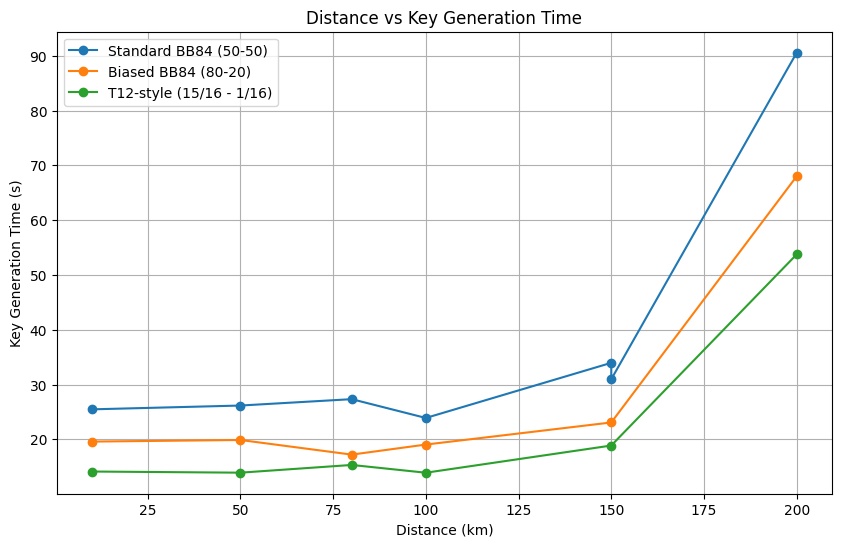

In [ ]:
# @title Plot: Distance vs Key Generation Time

plt.figure(figsize=(10, 6))

for protocol_name in protocols.keys():
    subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
    plt.plot(
        subset["Distance (km)"],
        subset["Keygen Time (s)"],
        marker="o",
        label=protocol_name
    )

plt.xlabel("Distance (km)")
plt.ylabel("Key Generation Time (s)")
plt.title("Distance vs Key Generation Time")
plt.legend()
plt.grid(True)
plt.savefig("Phase 1 Distance vs Key Generation Time", dpi=300, bbox_inches="tight")
plt.show()

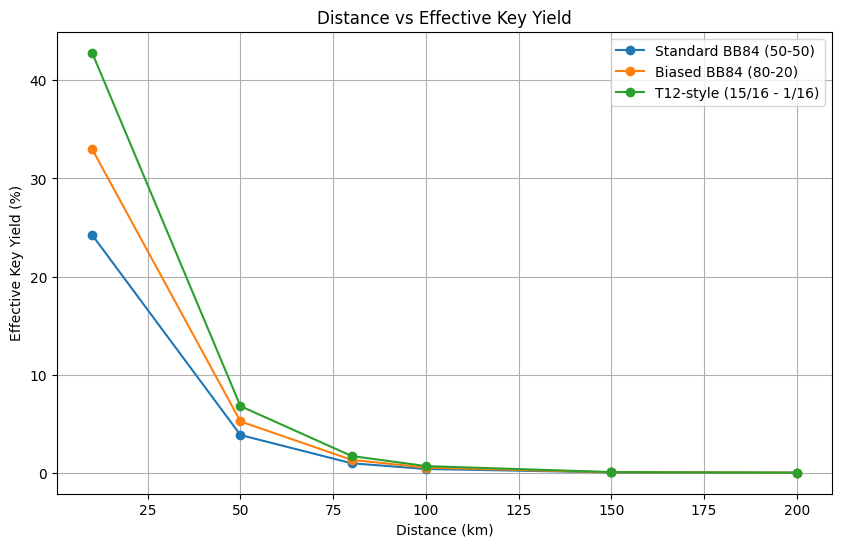

In [ ]:
# @title Plot: Distance vs Effective Key Yield

plt.figure(figsize=(10, 6))

for protocol_name in protocols.keys():
    subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
    plt.plot(
        subset["Distance (km)"],
        subset["Effective Key Yield (%)"],
        marker="o",
        label=protocol_name
    )

plt.xlabel("Distance (km)")
plt.ylabel("Effective Key Yield (%)")
plt.title("Distance vs Effective Key Yield")
plt.legend()
plt.grid(True)
plt.savefig("Phase 1 Distance vs Effective Key Yield", dpi=300, bbox_inches="tight")
plt.show()

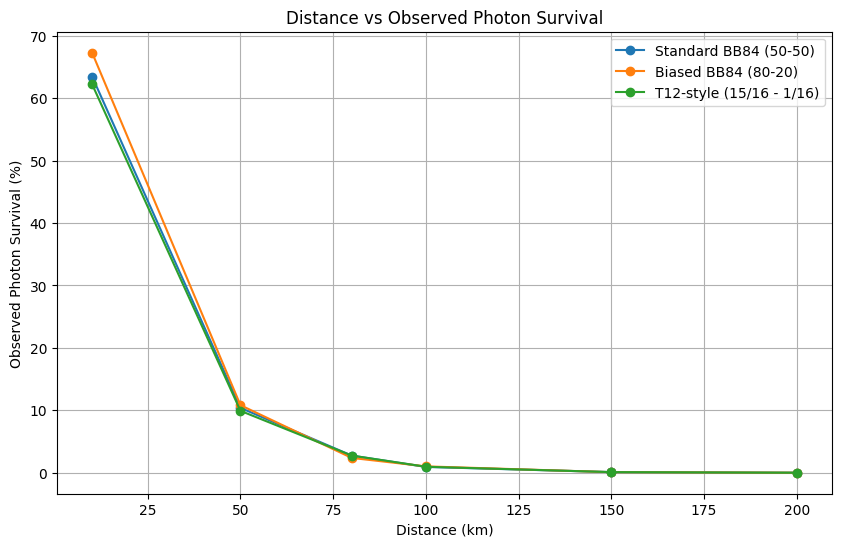

In [ ]:
# @title Plot: Distance vs Photon Survival

plt.figure(figsize=(10, 6))

for protocol_name in protocols.keys():
    subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
    plt.plot(
        subset["Distance (km)"],
        subset["Observed Photon Survival (%)"],
        marker="o",
        label=protocol_name
    )

plt.xlabel("Distance (km)")
plt.ylabel("Observed Photon Survival (%)")
plt.title("Distance vs Observed Photon Survival")
plt.legend()
plt.grid(True)
plt.savefig("Phase 1 Distance vs Observed Photon Survival", dpi=300, bbox_inches="tight")
plt.show()

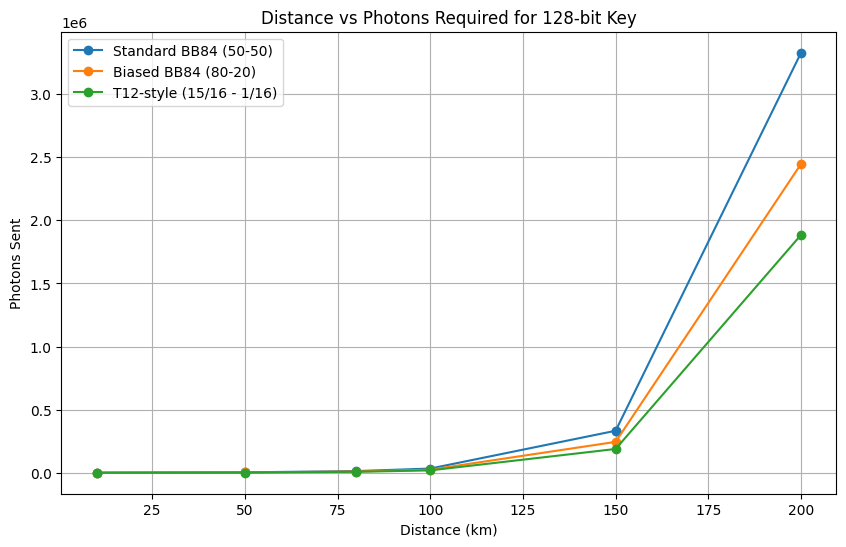

In [ ]:
# @title Plot: Distance vs Photons Sent

plt.figure(figsize=(10, 6))

for protocol_name in protocols.keys():
    subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
    plt.plot(
        subset["Distance (km)"],
        subset["Photons Sent"],
        marker="o",
        label=protocol_name
    )

plt.xlabel("Distance (km)")
plt.ylabel("Photons Sent")
plt.title("Distance vs Photons Required for 128-bit Key")
plt.legend()
plt.grid(True)
plt.savefig("Phase 1 Distance vs Photons Required for 128-bit Key", dpi=300, bbox_inches="tight")
plt.show()

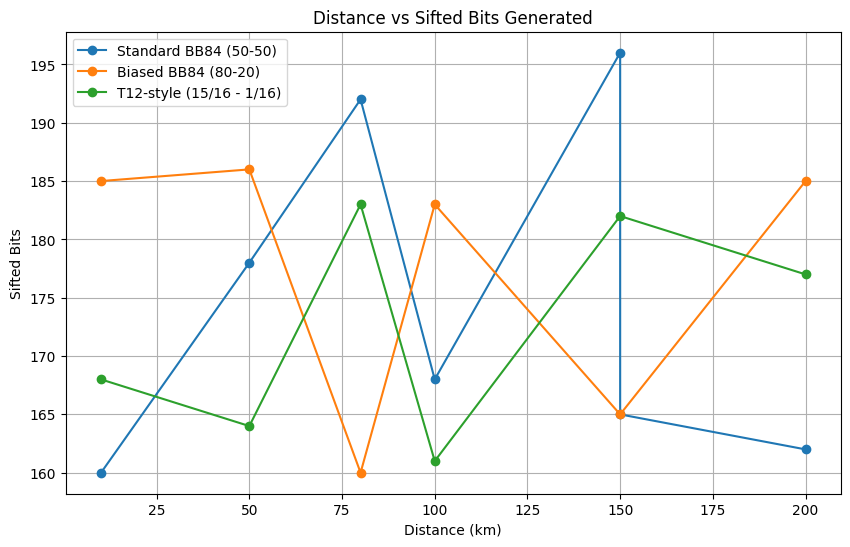

In [ ]:
# @title Plot: Distance vs Sifted Bits

plt.figure(figsize=(10, 6))

for protocol_name in protocols.keys():
    subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
    plt.plot(
        subset["Distance (km)"],
        subset["Sifted Bits"],
        marker="o",
        label=protocol_name
    )

plt.xlabel("Distance (km)")
plt.ylabel("Sifted Bits")
plt.title("Distance vs Sifted Bits Generated")
plt.legend()
plt.grid(True)
plt.savefig("Phase 1 Distance vs Sifted Bits Generated", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# @title Saving to CSV

df_distance_sweep.to_csv("distance_sweep_results.csv", index=False)